### ============================================================
### Load HC3 (Human ChatGPT Comparison Corpus) — Google Colab
### https://huggingface.co/datasets/Hello-SimpleAI/HC3  (config: "all")
### ============================================================

In [116]:
import pandas as pd

# HC3 is just jsonl files on the hub = one per domain (5 domains) + all.jsonl (JSONL store each row/line as 1 object)
# all 5 combined (finance, medicine, general Q&A, Reddit ELI5, and Wikipedia computer-science.)
# read it straight over the hf:// filesystem (huggingface_hub library), skip the datasets library and its script/config mess
hc3 = pd.read_json("hf://datasets/Hello-SimpleAI/HC3/all.jsonl", lines=True)

print(hc3.shape)                     # one row per question
print(hc3["source"].value_counts())  # questions per domain
hc3.head()

(24322, 5)
source
reddit_eli5    17112
finance         3933
medicine        1248
open_qa         1187
wiki_csai        842
Name: count, dtype: int64


,question,human_answers,chatgpt_answers,index,source
0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,NaN,reddit_eli5
1,"If salt is so bad for cars , why do we use it ...",[salt is good for not dying in car crashes and...,[Salt is used on roads to help melt ice and sn...,NaN,reddit_eli5
2,Why do we still have SD TV channels when HD lo...,[The way it works is that old TV stations got ...,[There are a few reasons why we still have SD ...,NaN,reddit_eli5
3,Why has nobody assassinated Kim Jong - un He i...,[You ca n't just go around assassinating the l...,[It is generally not acceptable or ethical to ...,NaN,reddit_eli5
4,How was airplane technology able to advance so...,[Wanting to kill the shit out of Germans drive...,[After the Wright Brothers made the first powe...,NaN,reddit_eli5


### HC3 dataset does not have any null values

In [117]:
print("Missing values:")
print(hc3[["question", "human_answers", "chatgpt_answers"]].isna().sum())

Missing values:
question           0
human_answers      0
chatgpt_answers    0
dtype: int64


In [118]:
hc3["human_word_count"] = hc3["human_answers"].apply(lambda x: len(x[0].split()) if len(x) > 0 else 0)
hc3["chatgpt_word_count"] = hc3["chatgpt_answers"].apply(lambda x: len(x[0].split()) if len(x) > 0 else 0)

print("Human answers with <=1 word:", (hc3["human_word_count"] <= 1).sum())
print("ChatGPT answers with <=1 word:", (hc3["chatgpt_word_count"] <= 1).sum())

hc3[
    (hc3["human_word_count"] <= 1) |
    (hc3["chatgpt_word_count"] <= 1)
][
    ["question", "human_answers", "chatgpt_answers",
     "human_word_count", "chatgpt_word_count"]
]

Human answers with <=1 word: 1
ChatGPT answers with <=1 word: 458


,question,human_answers,chatgpt_answers,human_word_count,chatgpt_word_count
8172,How is soil formed ? Is there soil on moon?If ...,[Does n't soil consist of a number of differen...,[],32,0
8173,What is earwax and why do we have it ? I was j...,[What is it ? Not sure what the chemical compo...,[],70,0
8438,"Why is it that Jalapeño is spelt with a "" J "" ...",[Because Spanish orthography has rules that di...,[],40,0
8439,What is the difference between mexican soda an...,[Soda made in the U.S. has been made from high...,[],111,0
8681,How is soil formed ? Is there soil on moon?If ...,[Does n't soil consist of a number of differen...,[],32,0
...,...,...,...,...,...
11723,Why do roller skates have such a negative resp...,[> They were the shit in the 90 's so what hap...,[],82,0
19909,"As a Sole Proprietor, will “employer” Solo 401...",[This seems to depend on what kind of corporat...,[还有就是办卡的手机号码没用了可挂失不如果您的手机号码没有用了，您可以考虑挂失您的银行卡。挂...,321,1
23177,"Pressure in temple, whooshing sensation. Is it...",[Hello],[It is possible that the sensation you are exp...,1,127
23832,"Kidney infection, weird twinges in bladder and...","[hi, urinary infections need to be treated. If...",[],72,0


In [119]:
hc3_clean = hc3[
    (hc3["human_answers"].apply(len) > 0) &
    (hc3["chatgpt_answers"].apply(len) > 0)
].copy()

print(hc3_clean.shape)
hc3_clean.head()

(23867, 7)


,question,human_answers,chatgpt_answers,index,source,human_word_count,chatgpt_word_count
0,"Why is every book I hear about a "" NY Times # ...","[Basically there are many categories of "" Best...",[There are many different best seller lists th...,NaN,reddit_eli5,134,207
1,"If salt is so bad for cars , why do we use it ...",[salt is good for not dying in car crashes and...,[Salt is used on roads to help melt ice and sn...,NaN,reddit_eli5,41,199
2,Why do we still have SD TV channels when HD lo...,[The way it works is that old TV stations got ...,[There are a few reasons why we still have SD ...,NaN,reddit_eli5,166,146
3,Why has nobody assassinated Kim Jong - un He i...,[You ca n't just go around assassinating the l...,[It is generally not acceptable or ethical to ...,NaN,reddit_eli5,122,145
4,How was airplane technology able to advance so...,[Wanting to kill the shit out of Germans drive...,[After the Wright Brothers made the first powe...,NaN,reddit_eli5,11,199


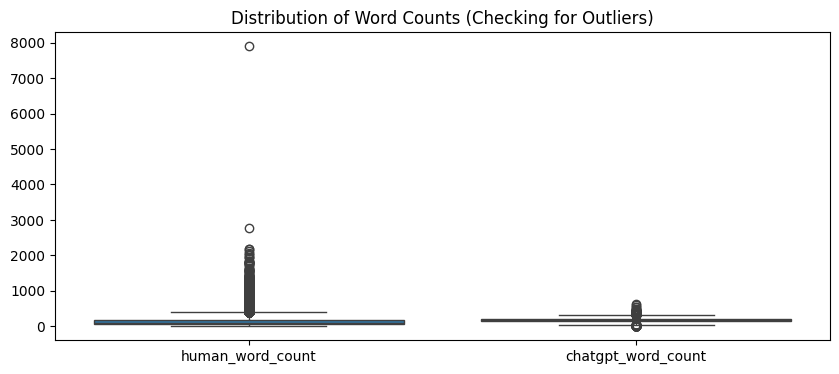

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.boxplot(data=hc3_clean[["human_word_count", "chatgpt_word_count"]])
plt.title("Distribution of Word Counts (Checking for Outliers)")
plt.show()

New maximum human word count: 2182


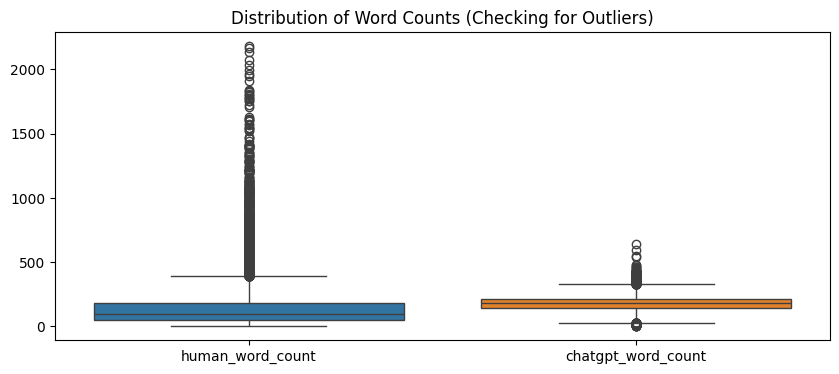

In [121]:
hc3_clean = hc3_clean[hc3_clean["human_word_count"] <= 2600].copy()
print("New maximum human word count:", hc3_clean["human_word_count"].max())

# New visualization after dropping the 8000 word count outlier

plt.figure(figsize=(10, 4))
sns.boxplot(data=hc3_clean[["human_word_count", "chatgpt_word_count"]])
plt.title("Distribution of Word Counts (Checking for Outliers)")
plt.show()

In [122]:
import re
import unicodedata

def normalize_text(text):
    if isinstance(text, list):
        return [normalize_text(x) for x in text]

    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text)  # replace weird spacing with one space
    text = text.strip()

    return text

hc3_clean["question"] = hc3_clean["question"].apply(normalize_text)
hc3_clean["human_answers_normalized"] = hc3_clean["human_answers"].apply(normalize_text)
hc3_clean["chatgpt_answers_normalized"] = hc3_clean["chatgpt_answers"].apply(normalize_text)

Drop duplicates

In [123]:
hc3_split = hc3_clean.drop_duplicates(subset=["question"]).copy()

**Train/ Test/ Validation Split**

breakdown summary:
- 80% train
- 10% test
- 10% validation

In [124]:
from sklearn.model_selection import train_test_split


In [125]:
#first split: 80% train and 20% other
train_questions, temp_questions = train_test_split(hc3_split, test_size=0.20, random_state=42, stratify=hc3_split["source"])

In [126]:
#split that remaining 20% evenly: 10% validation and 10% test
val_questions, test_questions = train_test_split(temp_questions, test_size=0.50, random_state=42, stratify=temp_questions["source"])

In [127]:
# print results to see number in each split
print("train questions:", len(train_questions))
print("validation questions:", len(val_questions))
print("test questions:", len(test_questions))

train questions: 18669
validation questions: 2334
test questions: 2334


In [128]:
def create_answer_dataset(df):

  # Human written answers
  human = df[["question", "source", "human_answers_normalized"]].explode("human_answers_normalized").copy()
  human = human.rename(columns={"human_answers_normalized": "text"})
  human["label"] = 0

  #AI generated answers
  ai = df[["question", "source", "chatgpt_answers_normalized"]].explode("chatgpt_answers_normalized").copy()
  ai = ai.rename(columns={"chatgpt_answers_normalized": "text"})
  ai["label"] = 1

  # Combine
  combined = pd.concat( [human, ai], ignore_index=True )

  return combined


In [129]:
train_df = create_answer_dataset(train_questions)
val_df = create_answer_dataset(val_questions)
test_df = create_answer_dataset(test_questions)

Convert each split into answer level data

In [130]:
#answer level split sizes
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (65548, 4)
Validation: (8213, 4)
Test: (8202, 4)


Leakage:

In [131]:
print("train/val overlap:", len(set(train_questions["question"]) & set(val_questions["question"])))
print("train/val overlap:", len(set(train_questions["question"]) & set(test_questions["question"])))
print("train/val overlap:", len(set(val_questions["question"]) & set(test_questions["question"])))

train/val overlap: 0
train/val overlap: 0
train/val overlap: 0


## 1. TF-IDF Feature Extraction

Convert text answers into numerical features using TF-IDF.

- Use unigrams and bigrams.
- Limit the vocabulary to 50,000 features.
- Fit TF-IDF on training data only to prevent data leakage.
- Use the same vectorizer to transform validation and test data.

In [132]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text to numerical features using the same settings
# as the September notebook.
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train = tfidf.fit_transform(train_df["text"])
X_val = tfidf.transform(val_df["text"])
X_test = tfidf.transform(test_df["text"])

# Labels: 0 = Human, 1 = AI
y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (65548, 50000)
Validation: (8213, 50000)
Test: (8202, 50000)


## 2. Dimensionality Reduction

TF-IDF produces 50,000 features, which may be computationally
expensive for Gradient Boosting.

Use TruncatedSVD to reduce the features to 100 components.

Fit SVD only on the training set to prevent leakage.
We will later experiment with different numbers of components.

In [133]:
from sklearn.decomposition import TruncatedSVD
import time

start = time.time()

# Reduce TF-IDF features from 50,000 to 100 dimensions.
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_train_reduced = svd.fit_transform(X_train)
X_val_reduced = svd.transform(X_val)

print("Reduced train shape:", X_train_reduced.shape)
print("Reduced validation shape:", X_val_reduced.shape)

print("Explained variance:",
      svd.explained_variance_ratio_.sum())

print(f"SVD time: {time.time() - start:.2f} seconds")

/Users/elizalamar/Documents/BTT/Chewy-1A-spot-the-bot-detecting-ai-generated-text/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:590: RuntimeWarning: divide by zero encountered in matmul
  U = Q @ Uhat
/Users/elizalamar/Documents/BTT/Chewy-1A-spot-the-bot-detecting-ai-generated-text/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:590: RuntimeWarning: overflow encountered in matmul
  U = Q @ Uhat
/Users/elizalamar/Documents/BTT/Chewy-1A-spot-the-bot-detecting-ai-generated-text/.venv/lib/python3.10/site-packages/sklearn/utils/extmath.py:590: RuntimeWarning: invalid value encountered in matmul
  U = Q @ Uhat


Reduced train shape: (65548, 100)
Reduced validation shape: (8213, 100)
Explained variance: 0.07581780455363987
SVD time: 8.47 seconds


## 3. Baseline Gradient Boosting

Train a HistGradientBoostingClassifier using the reduced
TF-IDF features.

Initial hyperparameters:
- max_iter = 100: Number of boosting stages
- learning_rate = 0.1: Contribution of each boosting stage
- max_leaf_nodes = 31: Maximum number of leaves per tree

These serve as the baseline before hyperparameter tuning.

              precision    recall  f1-score   support

           0       0.97      0.98      0.98      5560
           1       0.97      0.94      0.95      2653

    accuracy                           0.97      8213
   macro avg       0.97      0.96      0.97      8213
weighted avg       0.97      0.97      0.97      8213

Macro-F1: 0.9663919763042904


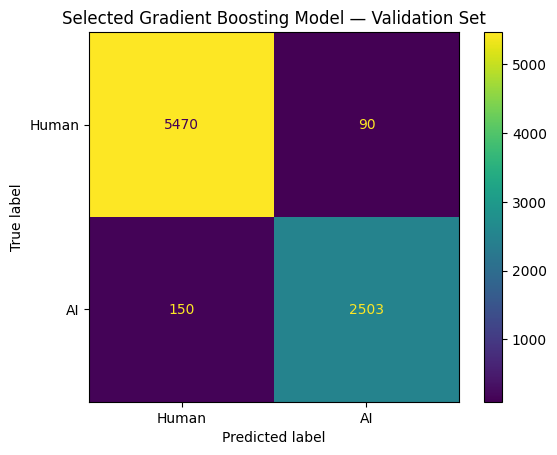

In [134]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    early_stopping=False,
    random_state=42
)

best_model.fit(X_train_reduced, y_train)
best_val_pred = best_model.predict(X_val_reduced)

print(classification_report(y_val, best_val_pred))
print("Macro-F1:", f1_score(y_val, best_val_pred, average="macro"))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_val_pred,
    display_labels=["Human", "AI"]
)

plt.title("Selected Gradient Boosting Model — Validation Set")
plt.show()

## 4. Baseline Evaluation

Evaluate the baseline model on validation data.

We use macro-F1 as the primary metric because we want
to measure performance on both human and AI responses.

The test set is reserved for final model evaluation.

Accuracy: 0.9633507853403142
Macro-F1: 0.9577684935348689

Classification Report:
              precision    recall  f1-score   support

       Human       0.97      0.98      0.97      5560
          AI       0.96      0.93      0.94      2653

    accuracy                           0.96      8213
   macro avg       0.96      0.95      0.96      8213
weighted avg       0.96      0.96      0.96      8213



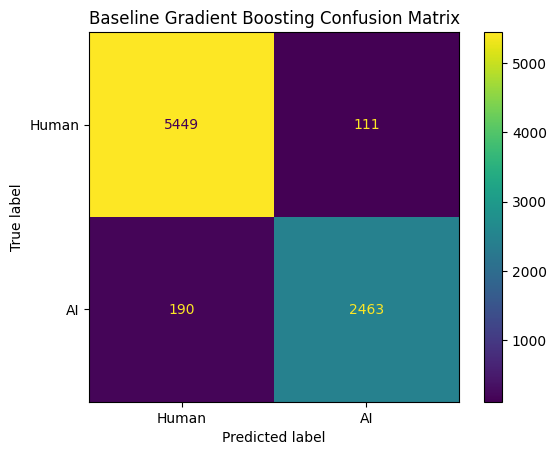

In [135]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Predict labels using the validation set.
baseline_pred = baseline.predict(X_val_reduced)

# Calculate evaluation metrics.
baseline_accuracy = accuracy_score(y_val, baseline_pred)
baseline_f1 = f1_score(y_val, baseline_pred, average="macro")

print("Accuracy:", baseline_accuracy)
print("Macro-F1:", baseline_f1)

print("\nClassification Report:")
print(classification_report(
    y_val,
    baseline_pred,
    target_names=["Human", "AI"]
))

# Visualize incorrect and correct classifications.
ConfusionMatrixDisplay.from_predictions(
    y_val,
    baseline_pred,
    display_labels=["Human", "AI"]
)

plt.title("Baseline Gradient Boosting Confusion Matrix")
plt.show()

## 5. Hyperparameter Tuning

### Experiment 1: Number of Boosting Stages

Test max_iter = 50, 100, and 200 while holding the
other parameters constant.

Compare training and validation macro-F1 to investigate
whether additional boosting stages improve performance
or lead to overfitting.

In [136]:
results = []

for n_trees in [50, 100, 200]:

    model = HistGradientBoostingClassifier(
        max_iter=n_trees,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42,
        early_stopping=False
    )

    model.fit(X_train_reduced, y_train)

    train_pred = model.predict(X_train_reduced)
    val_pred = model.predict(X_val_reduced)

    results.append({
        "max_iter": n_trees,
        "train_f1": f1_score(y_train, train_pred, average="macro"),
        "val_f1": f1_score(y_val, val_pred, average="macro")
    })

results_df = pd.DataFrame(results)

display(results_df)

,max_iter,train_f1,val_f1
0,50,0.956914,0.945151
1,100,0.975394,0.958355
2,200,0.991892,0.966392


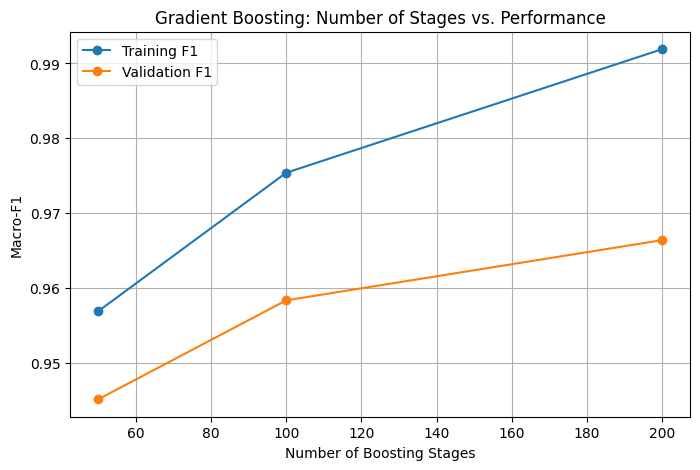

In [137]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["max_iter"],
    results_df["train_f1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    results_df["max_iter"],
    results_df["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Number of Boosting Stages")
plt.ylabel("Macro-F1")
plt.title("Gradient Boosting: Number of Stages vs. Performance")
plt.legend()
plt.grid(True)
plt.show()

### Experiment 2: Learning Rate and Tree Complexity

We compare learning rates of 0.05 and 0.1 and maximum
leaf counts of 7, 15, and 31.

We hold max_iter at 200, the best-performing value
from Experiment 1.

Goal: Determine whether smaller learning rates or
simpler trees improve validation performance.

In [138]:
from itertools import product

results_2 = []

# Test all six combinations.
for lr, leaves in product([0.05, 0.1], [7, 15, 31]):

    model = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=lr,
        max_leaf_nodes=leaves,
        early_stopping=False,
        random_state=42
    )

    model.fit(X_train_reduced, y_train)

    train_pred = model.predict(X_train_reduced)
    val_pred = model.predict(X_val_reduced)

    results_2.append({
        "learning_rate": lr,
        "max_leaf_nodes": leaves,
        "train_f1": f1_score(y_train, train_pred, average="macro"),
        "val_f1": f1_score(y_val, val_pred, average="macro")
    })

results_2_df = pd.DataFrame(results_2)

# Display best-performing configurations first.
display(results_2_df.sort_values("val_f1", ascending=False))


,learning_rate,max_leaf_nodes,train_f1,val_f1
5,0.10,31,0.991892,0.966392
4,0.10,15,0.976905,0.962721
2,0.05,31,0.976014,0.958228
3,0.10,7,0.962267,0.956212
1,0.05,15,0.962687,0.952388
0,0.05,7,0.947814,0.941878


In [139]:
best_config = results_2_df.loc[
    results_2_df["val_f1"].idxmax()
]

print(best_config)

learning_rate      0.100000
max_leaf_nodes    31.000000
train_f1           0.991892
val_f1             0.966392
Name: 5, dtype: float64


Validation Accuracy: 0.9707780348228419
Validation Macro-F1: 0.9663919763042904

Classification Report:
              precision    recall  f1-score   support

       Human       0.97      0.98      0.98      5560
          AI       0.97      0.94      0.95      2653

    accuracy                           0.97      8213
   macro avg       0.97      0.96      0.97      8213
weighted avg       0.97      0.97      0.97      8213



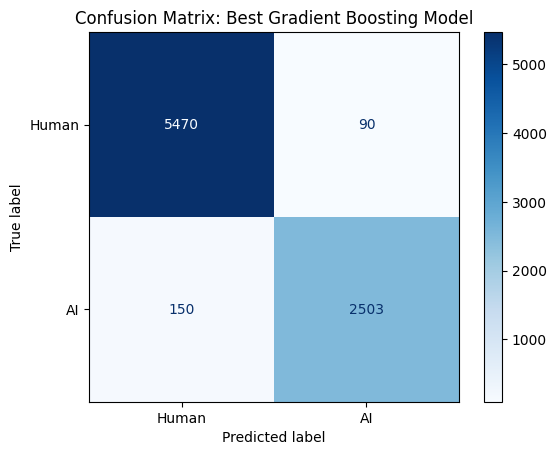

In [140]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

# Final chosen hyperparameters from tuning
best_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    early_stopping=False,
    random_state=42
)

best_model.fit(X_train_reduced, y_train)
best_val_pred = best_model.predict(X_val_reduced)

best_accuracy = accuracy_score(y_val, best_val_pred)
best_macro_f1 = f1_score(y_val, best_val_pred, average="macro")

print("Validation Accuracy:", best_accuracy)
print("Validation Macro-F1:", best_macro_f1)
print("\nClassification Report:")
print(classification_report(y_val, best_val_pred, target_names=["Human", "AI"]))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    best_val_pred,
    display_labels=["Human", "AI"],
    cmap="Blues"
)

plt.title("Confusion Matrix: Best Gradient Boosting Model")
plt.show()

## 8. Findings

### Baseline
- **Accuracy:** 96.34%
- **Macro-F1:** 0.9578
- **Training time:** 2.16 seconds
- **SVD explained variance:** 7.58%

### Experiment 1: Number of Boosting Stages
- **Best max_iter:** 200
- **Highest validation macro-F1:** 0.9664
- **Evidence of potential overfitting:** The gap between training and validation macro-F1 increased, reaching 0.9919 versus 0.9664 at 200 boosting stages. This suggests potential overfitting, although validation performance continued improving.

### Experiment 2: Learning Rate and Tree Complexity
- Tested combinations of `learning_rate` in {0.05, 0.1} and `max_leaf_nodes` in {7, 15, 31}, while holding `max_iter = 200`.
- The best-performing configuration was:
  - **learning_rate = 0.1**
  - **max_leaf_nodes = 31**
- This configuration produced the strongest validation macro-F1 among the tested settings.

### Final Selected Hyperparameters
- **max_iter = 200**
- **learning_rate = 0.1**
- **max_leaf_nodes = 31**
- **early_stopping = False**
- **n_components = 100** for TruncatedSVD

### Interpretation
- Increasing the number of boosting stages improved validation performance from 50 to 200 stages.
- A learning rate of 0.1 performed better than 0.05 within the tested configurations.
- Allowing more leaf nodes improved validation performance, with 31 leaf nodes performing best.
- Although training performance was higher than validation performance, the best validation macro-F1 occurred at the highest number of boosting stages tested.

### Limitations / Next Steps
- Compare Gradient Boosting results directly against the Linear SVM baseline.
- TruncatedSVD retained approximately 7.58% of TF-IDF variance using 100 components. Experiment with different numbers of components to determine whether useful predictive information is being discarded.
- Evaluate the selected model on the held-out test set only after model selection is complete.